[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch63_LabCh63_Fool_It_Then_Calibrate_It.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 63: Robustness, Uncertainty and Calibration** (Part XIV: Trust and Craft).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=63](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=63)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch63 - Fool it, then calibrate it
## Attack a classifier, shift its inputs, check its confidence, and teach it to say "I do not know"

This lab goes with **Chapter 63** of *The Why Book of Deep Learning, Part 2*.

Every lab so far ended with a test accuracy, measured on clean images drawn from the same collection as the
training images. That is the easy exam. Here you train one small clothing classifier and then set it four
harder ones.

| Part | Question | Steps |
|---|---|---|
| One: fool it | How small a change, chosen with the gradient, flips the answer? | 5 to 9 |
| Two: shift it | What happens when the camera tilts, the sensor gets noisy or the lens blurs? | 10 |
| Three: calibrate it | When it says 80% sure, is it right 80% of the time? | 11 to 13 |
| Four: know when it does not know | Handwritten digits, an ensemble, abstaining, and prediction sets | 14 to 19 |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Write the fast gradient sign attack and an iterative attack with `tf.GradientTape` | Steps 5 to 8 |
| Train a model on attacked images and measure what that buys and what it costs | Step 9 |
| Measure accuracy against the severity of a corruption | Step 10 |
| Draw a reliability diagram and compute the expected calibration error | Steps 11 and 12 |
| Fit one temperature on validation data and show that accuracy cannot change | Steps 12 and 13 |
| Score out-of-distribution detection, build a small ensemble, and run MC dropout | Steps 14 to 16 |
| Set an abstention threshold, draw the accuracy-coverage curve, and build conformal prediction sets | Steps 18 and 19 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** a little over five minutes on a laptop CPU. No GPU is needed.

> **Honest scale:** this is a miniature. The model has about 57 thousand parameters and sees 28 x 28 grey
> images for four passes. Several results below depend on that: a small network trained briefly is not
> confident in the way a large network trained for days is, and a low-resolution grey image has only 784
> directions to push in. The methods carry over to full-size systems. The numbers do not.

---
## Step 1 - Imports and one seed

In [1]:
import os, time, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 63
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True, linewidth=120)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPUs visible:", len(tf.config.list_physical_devices("GPU")))

TensorFlow 2.21.0 | Keras 3.14.1


GPUs visible: 0


---
## Step 2 - The data: clothing to learn from, digits to be confused by

The model learns **Fashion-MNIST**: ten kinds of clothing.

- `x_fit`: 50,000 images for training.
- `x_val`: 10,000 images held out. In this lab they have a real job: the temperature (Step 12), the abstention
  threshold (Step 18) and the conformal threshold (Step 19) are all chosen on them.
- `x_test`: 10,000 images that nothing is ever chosen on.
- `x_att`: the first 2,000 test images. Attacks need a gradient for every image, so we attack a subset.
- `x_ood`: 10,000 **handwritten digits** from MNIST. Same size, same grey scale, and nothing to do with
  clothing. They are our **out-of-distribution** inputs.

Pixels are scaled to the range 0 to 1 here, outside the model, because an attack is a change to the pixels and
we want its size in the same units as the pixels.

> **Predict:** the model will have ten outputs, all of them clothing. When it is shown a handwritten 7, what
> can it answer? How sure do you expect it to be?

In [2]:
NAMES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Boot"]

(x_tr, y_tr), (x_te, y_te) = keras.datasets.fashion_mnist.load_data()
prep = lambda a: (a.astype("float32") / 255.0)[..., None]
order = rng.permutation(len(x_tr))
x_tr, y_tr = prep(x_tr[order]), y_tr[order].astype("int64")
x_fit, y_fit = x_tr[:50000], y_tr[:50000]
x_val, y_val = x_tr[50000:], y_tr[50000:]
x_test, y_test = prep(x_te), y_te.astype("int64")
x_att, y_att = x_test[:2000], y_test[:2000]

(_, _), (x_digits, y_digits) = keras.datasets.mnist.load_data()
x_ood = prep(x_digits)

for name, a in [("x_fit", x_fit), ("x_val", x_val), ("x_test", x_test), ("x_att", x_att), ("x_ood", x_ood)]:
    print(f"{name:7s} {str(a.shape):20s} {a.dtype}  min {a.min():.0f}  max {a.max():.0f}  mean {a.mean():.3f}")

x_fit   (50000, 28, 28, 1)   float32  min 0  max 1  mean 0.286
x_val   (10000, 28, 28, 1)   float32  min 0  max 1  mean 0.285
x_test  (10000, 28, 28, 1)   float32  min 0  max 1  mean 0.287
x_att   (2000, 28, 28, 1)    float32  min 0  max 1  mean 0.287
x_ood   (10000, 28, 28, 1)   float32  min 0  max 1  mean 0.133


---
## Step 3 - The model, and why it ends in logits

Two convolution blocks, a dropout layer, one hidden Dense layer and ten outputs. Two choices matter later.

- The last layer has **no softmax**. It returns ten raw scores, the **logits** (Chapter 5). Temperature scaling
  in Step 12 divides the logits by a number before the softmax, so we need to get at them.
- There is a **Dropout** layer. During training it is on, at prediction time Keras turns it off (Chapter 11).
  In Step 16 we deliberately leave it on.

The counting rules are Chapter 14's: a convolution has `(k * k * channels_in + 1) * filters` parameters and a
Dense layer has `(inputs + 1) * units`.

> **Predict:** which layer holds most of the parameters? Work out the total before you run the cell.

In [3]:
def build_model(dropout=0.3, name="clothes"):
    return keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(16, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dropout(dropout),
        layers.Dense(64, activation="relu"),
        layers.Dense(10),                               # logits: no softmax here
    ], name=name)

loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)

def compiled(model):
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=loss_fn, metrics=["accuracy"])
    return model

base = compiled(build_model())
base.summary()
by_hand = (3 * 3 * 1 + 1) * 16 + (3 * 3 * 16 + 1) * 32 + (5 * 5 * 32 + 1) * 64 + (64 + 1) * 10
print("by hand: 160 + 4,640 + 51,264 + 650 =", f"{by_hand:,}")
assert base.count_params() == by_hand == 56714

Model: "clothes"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

by hand: 160 + 4,640 + 51,264 + 650 = 56,714


---
## Step 4 - Train it, and take the easy exam

Four passes over 50,000 images. Then the number every earlier lab stopped at: accuracy on clean test images.
We also print the **mean confidence**: the average of the largest softmax probability. Keep both in mind.

The small helpers defined here are used all the way down: `logits_of` runs a model, `softmax` turns logits
into probabilities (with an optional temperature `T`), `accuracy` and `nll` score them.

> **Predict:** will the mean confidence be above or below the accuracy? (The usual story about deep networks
> says above. This is a small network trained for four passes with dropout.)

In [4]:
EPOCHS = 4

def logits_of(model, x):
    return model.predict(x, batch_size=1000, verbose=0)

def softmax(z, T=1.0):
    z = z / T
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def accuracy(p, y):
    return float((p.argmax(1) == y).mean())

def nll(p, y):                                           # mean cross-entropy, from probabilities
    return float(-np.log(p[np.arange(len(y)), y] + 1e-12).mean())

t0 = time.time()
base.fit(x_fit, y_fit, epochs=EPOCHS, batch_size=128, validation_data=(x_val, y_val), verbose=2)
print(f"training took {time.time() - t0:.0f}s")

z_val, z_test = logits_of(base, x_val), logits_of(base, x_test)
p_val, p_test = softmax(z_val), softmax(z_test)
print(f"\nvalidation accuracy {accuracy(p_val, y_val):.2%}")
print(f"test accuracy       {accuracy(p_test, y_test):.2%}   mean confidence {p_test.max(1).mean():.2%}")
print("accuracy per class:", "  ".join(f"{NAMES[c]} {accuracy(p_test[y_test == c], y_test[y_test == c]):.0%}" for c in range(10)))

Epoch 1/4


391/391 - 4s - 10ms/step - accuracy: 0.7527 - loss: 0.6960 - val_accuracy: 0.8314 - val_loss: 0.4554


Epoch 2/4


391/391 - 3s - 8ms/step - accuracy: 0.8322 - loss: 0.4593 - val_accuracy: 0.8572 - val_loss: 0.3992


Epoch 3/4


391/391 - 4s - 9ms/step - accuracy: 0.8475 - loss: 0.4145 - val_accuracy: 0.8691 - val_loss: 0.3652


Epoch 4/4


391/391 - 3s - 8ms/step - accuracy: 0.8597 - loss: 0.3827 - val_accuracy: 0.8787 - val_loss: 0.3393


training took 14s



validation accuracy 87.87%
test accuracy       87.36%   mean confidence 85.73%
accuracy per class: T-shirt 84%  Trouser 97%  Pullover 78%  Dress 92%  Coat 76%  Sandal 98%  Shirt 63%  Sneaker 93%  Bag 97%  Boot 95%


---
# Part one: fool it

## Step 5 - The fast gradient sign step, on four numbers

Training asks: *which way should each weight move to make the loss smaller?* An attack asks the mirror
question: *which way should each **pixel** move to make the loss **larger**?* The gradient of the loss with
respect to the input answers it. The **fast gradient sign method** (FGSM, 2014) keeps only the sign of that
gradient and moves every input by the same small amount `eps` in that direction.

Here it is on a model small enough to do by hand: one neuron with four inputs and a sigmoid (Chapter 3). The
true label is 1. For this model the gradient of the loss with respect to the input is `(p - 1) * w`, so each
input moves **against the sign of its weight**, and the score falls by exactly `eps * sum(|w|)`.

Then the same sum for more inputs. If every input contributes a little, the total grows with the number of
inputs while the size of each step stays `eps`.

> **Predict:** with `eps = 0.1` the score starts at 1.1. Where does it end? Does `eps = 0.2` flip the answer?

In [5]:
w = np.array([2.0, -1.0, 0.5, -3.0])
x0 = np.array([0.6, 0.2, 0.8, 0.1])
sig = lambda z: 1 / (1 + np.exp(-z))
z0 = w @ x0
p0 = sig(z0)
grad_x = (p0 - 1.0) * w                                  # d loss / d x for true label 1
print("score z =", round(float(z0), 3), "  p(label 1) =", round(float(p0), 3))
print("gradient of the loss w.r.t. x:", grad_x, "  sign:", np.sign(grad_x))
print("sum of |w| =", np.abs(w).sum())
for eps in [0.1, 0.2]:
    xa = x0 + eps * np.sign(grad_x)
    za = w @ xa
    print(f"eps {eps}: x' = {xa}  score {za:.2f} (moved {za - z0:+.2f} = -eps * {np.abs(w).sum()})  p = {sig(za):.3f}")

print("\nThe same push with more inputs, if the average |w| is 0.05 and eps = 0.02 (5 grey levels in 255):")
for n, what in [(4, "our toy"), (784, "a 28 x 28 grey image"), (150528, "a 224 x 224 colour image")]:
    print(f"  {n:7,d} inputs ({what}): score moves by 0.02 * {n:,} * 0.05 = {0.02 * n * 0.05:,.3f}")

score z = 1.1   p(label 1) = 0.75
gradient of the loss w.r.t. x: [-0.499  0.25  -0.125  0.749]   sign: [-1.  1. -1.  1.]
sum of |w| = 6.5
eps 0.1: x' = [0.5 0.3 0.7 0.2]  score 0.45 (moved -0.65 = -eps * 6.5)  p = 0.611
eps 0.2: x' = [0.4 0.4 0.6 0.3]  score -0.20 (moved -1.30 = -eps * 6.5)  p = 0.450

The same push with more inputs, if the average |w| is 0.05 and eps = 0.02 (5 grey levels in 255):
        4 inputs (our toy): score moves by 0.02 * 4 * 0.05 = 0.004
      784 inputs (a 28 x 28 grey image): score moves by 0.02 * 784 * 0.05 = 0.784
  150,528 inputs (a 224 x 224 colour image): score moves by 0.02 * 150,528 * 0.05 = 150.528


---
## Step 6 - FGSM on the real model, and accuracy against the size of the step

Now the same thing with `tf.GradientTape`. Chapter 7 used the tape to get gradients for the weights. Here we
tell it to **watch the image** and ask for the gradient of the loss with respect to the pixels. The weights
do not change at all.

`fgsm` returns `clip(x + eps * sign(gradient), 0, 1)`. No pixel moves by more than `eps`. For scale, one grey
level is 1/255 = 0.004, so `eps = 0.02` is about 5 grey levels.

The control matters as much as the attack: `random_signs` moves every pixel by the same `eps`, up or down at
random. Same size of change, no gradient.

The cell also checks the story of Step 5 on this network: for a small step, the loss should rise by about
`eps` times the sum of the absolute values of the gradient.

> **Predict:** at `eps = 0.05` (13 grey levels), what accuracy is left under the attack? And under random
> signs of the same size?

mean of sum |gradient| over the 784 pixels: 16.89
eps = 0.002: predicted rise in loss 0.0338, measured rise 0.0328

  eps  grey levels   FGSM accuracy   random signs   mean confidence of the FGSM mistakes


0.000        0.0          88.5%         88.5%          63.1%


0.005        1.3          85.0%         88.3%          63.3%


0.010        2.6          81.5%         88.2%          63.9%


0.020        5.1          73.4%         87.7%          64.7%


0.030        7.6          65.3%         87.8%          66.1%


0.050       12.8          51.9%         87.5%          69.9%


0.075       19.1          35.4%         86.6%          73.0%


0.100       25.5          22.6%         85.4%          75.2%


0.150       38.2           9.4%         81.0%          77.6%


0.200       51.0           3.5%         76.0%          78.6%


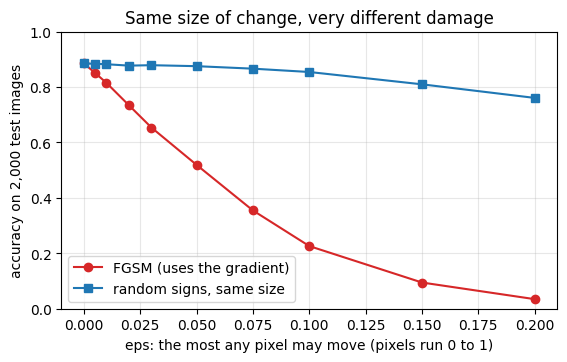

In [6]:
per_example_loss = keras.losses.SparseCategoricalCrossentropy(from_logits=True, reduction="none")

def input_gradient(model, x, y, batch=1000):
    """Gradient of each image's own loss with respect to its pixels."""
    out = []
    for i in range(0, len(x), batch):
        xb = tf.convert_to_tensor(x[i:i + batch])
        with tf.GradientTape() as tape:
            tape.watch(xb)                               # the image is the variable now
            loss = tf.reduce_sum(per_example_loss(y[i:i + batch], model(xb, training=False)))
        out.append(tape.gradient(loss, xb).numpy())
    return np.concatenate(out)

def fgsm(model, x, y, eps):
    return np.clip(x + eps * np.sign(input_gradient(model, x, y)), 0.0, 1.0).astype("float32")

def random_signs(x, eps, seed=0):
    s = np.random.default_rng(seed).choice([-1.0, 1.0], size=x.shape)
    return np.clip(x + eps * s, 0.0, 1.0).astype("float32")

def acc_on(model, x, y):
    return accuracy(softmax(logits_of(model, x)), y)

g = input_gradient(base, x_att, y_att)
l1 = np.abs(g).reshape(len(g), -1).sum(1)
loss_before = per_example_loss(y_att, base(x_att, training=False)).numpy()
tiny = 0.002
x_tiny = (x_att + tiny * np.sign(g)).astype("float32")              # not clipped: a pure test of the linear story
loss_after = per_example_loss(y_att, base(x_tiny, training=False)).numpy()
print(f"mean of sum |gradient| over the 784 pixels: {l1.mean():.2f}")
print(f"eps = {tiny}: predicted rise in loss {tiny * l1.mean():.4f}, measured rise {np.mean(loss_after - loss_before):.4f}")

EPS = [0.0, 0.005, 0.01, 0.02, 0.03, 0.05, 0.075, 0.1, 0.15, 0.2]
acc_fgsm, acc_rand, conf_wrong = [], [], []
print("\n  eps  grey levels   FGSM accuracy   random signs   mean confidence of the FGSM mistakes")
for eps in EPS:
    xa = fgsm(base, x_att, y_att, eps)
    pa = softmax(logits_of(base, xa))
    wrong = pa.argmax(1) != y_att
    acc_fgsm.append(accuracy(pa, y_att)); acc_rand.append(acc_on(base, random_signs(x_att, eps), y_att))
    conf_wrong.append(pa.max(1)[wrong].mean())
    print(f"{eps:5.3f}  {eps * 255:9.1f}   {acc_fgsm[-1]:12.1%}   {acc_rand[-1]:11.1%}   {conf_wrong[-1]:12.1%}")

plt.figure(figsize=(6.4, 3.6))
plt.plot(EPS, acc_fgsm, "o-", color="tab:red", label="FGSM (uses the gradient)")
plt.plot(EPS, acc_rand, "s-", color="tab:blue", label="random signs, same size")
plt.xlabel("eps: the most any pixel may move (pixels run 0 to 1)"); plt.ylabel("accuracy on 2,000 test images")
plt.ylim(0, 1); plt.grid(alpha=0.3); plt.legend(); plt.title("Same size of change, very different damage"); plt.show()

### Why we see this

The two curves are the same *amount* of change. In both, every pixel moves by exactly `eps`. The difference is
direction. Random signs push some pixels the harmful way and some the helpful way, and the pushes mostly
cancel. FGSM makes all 784 pushes agree. This is the **linear explanation** of adversarial examples: many tiny
pushes, each in the worst direction, add up.

Read the last column too. The `eps = 0` row is the model's honest mistakes on clean images. As the attack
grows, the mistakes are held with **more** confidence, not less: the attack does not confuse the model, it
persuades it.

---
## Step 7 - Look at one: original, perturbation, adversarial

Numbers do not show how small the change is. Pictures do. For five test images the model gets right, the cell
draws the original, the perturbation `eps * sign(gradient)` (grey means "no change"; it can only be one of
three values), and their sum.

> **Predict:** at `eps = 0.05`, will you be able to see the difference between the top row and the bottom row?

right before the attack: 1770 of 2000; of those, flipped at eps = 0.05: 732


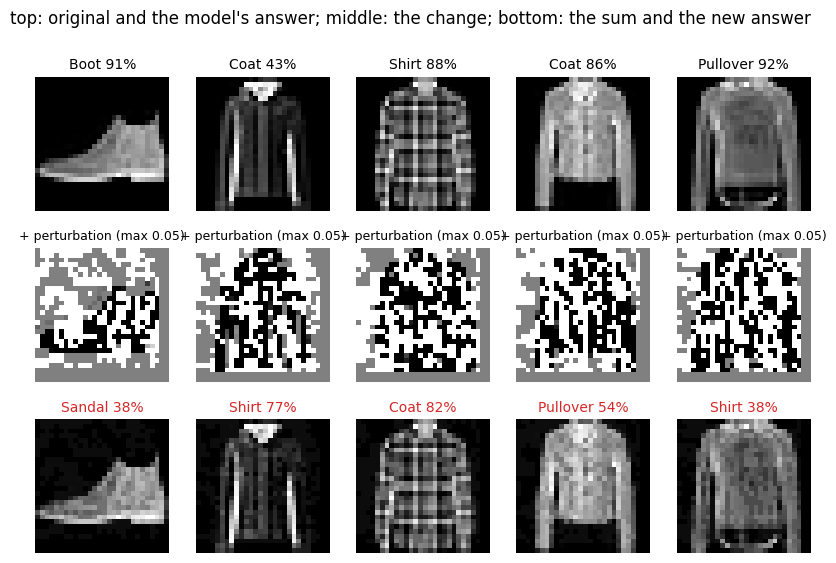

image 0: true Boot       before Boot      90.5%   after Sandal    38.4%   largest pixel change 0.050
image 6: true Coat       before Coat      42.7%   after Shirt     76.7%   largest pixel change 0.050
image 7: true Shirt      before Shirt     88.0%   after Coat      81.7%   largest pixel change 0.050
image 10: true Coat       before Coat      86.0%   after Pullover  53.9%   largest pixel change 0.050
image 16: true Pullover   before Pullover  92.0%   after Shirt     38.5%   largest pixel change 0.050


In [7]:
EPS_SHOW = 0.05
x_adv = fgsm(base, x_att, y_att, EPS_SHOW)
p_clean, p_adv = softmax(logits_of(base, x_att)), softmax(logits_of(base, x_adv))
flipped = np.where((p_clean.argmax(1) == y_att) & (p_adv.argmax(1) != y_att))[0]
print(f"right before the attack: {(p_clean.argmax(1) == y_att).sum()} of {len(y_att)};"
      f" of those, flipped at eps = {EPS_SHOW}: {len(flipped)}")
show = flipped[:5]
fig, ax = plt.subplots(3, 5, figsize=(10, 6.3))
for j, i in enumerate(show):
    ax[0, j].imshow(x_att[i, ..., 0], cmap="gray", vmin=0, vmax=1)
    ax[0, j].set_title(f"{NAMES[p_clean[i].argmax()]} {p_clean[i].max():.0%}", fontsize=10)
    ax[1, j].imshow((x_adv[i] - x_att[i])[..., 0], cmap="gray", vmin=-EPS_SHOW, vmax=EPS_SHOW)
    ax[1, j].set_title(f"+ perturbation (max {EPS_SHOW})", fontsize=9)
    ax[2, j].imshow(x_adv[i, ..., 0], cmap="gray", vmin=0, vmax=1)
    ax[2, j].set_title(f"{NAMES[p_adv[i].argmax()]} {p_adv[i].max():.0%}", fontsize=10, color="tab:red")
for a in ax.ravel():
    a.axis("off")
plt.suptitle("top: original and the model's answer; middle: the change; bottom: the sum and the new answer"); plt.show()
for i in show:
    print(f"image {i}: true {NAMES[y_att[i]]:9s}  before {NAMES[p_clean[i].argmax()]:9s} {p_clean[i].max():.1%}"
          f"   after {NAMES[p_adv[i].argmax()]:9s} {p_adv[i].max():.1%}   largest pixel change {np.abs(x_adv[i] - x_att[i]).max():.3f}")

---
## Step 8 - A stronger attack: many small steps

FGSM takes one step and trusts that the loss is a straight slope. It is not quite. An **iterative** attack
takes several smaller steps, asking for a fresh gradient each time, and after every step pulls the image back
inside the allowed box (no pixel more than `eps` from the original). Started from a random point inside the
box, this is **projected gradient descent**, PGD (2017), and it is the standard attack to test a defence
against. (It climbs the loss, so "ascent" would be the better word. The name stuck.)

> **Predict:** same `eps`, ten steps instead of one. Will the accuracy be lower, the same, or higher than
> under FGSM? By a lot or a little?

In [8]:
def pgd(model, x, y, eps, steps=10, seed=0):
    alpha = 2.5 * eps / steps                            # step size: enough to cross the box and come back
    xa = x + np.random.default_rng(seed).uniform(-eps, eps, size=x.shape).astype("float32")
    xa = np.clip(xa, 0.0, 1.0)
    for _ in range(steps):
        xa = xa + alpha * np.sign(input_gradient(model, xa, y))
        xa = np.clip(np.clip(xa, x - eps, x + eps), 0.0, 1.0).astype("float32")     # project back into the box
    return xa

print("  eps   clean    FGSM (1 step)   PGD (10 steps)")
clean_att = acc_on(base, x_att, y_att)
pgd_base = {}
for eps in [0.01, 0.02, 0.05]:
    pgd_base[eps] = acc_on(base, pgd(base, x_att, y_att, eps), y_att)
    print(f"{eps:5.2f}  {clean_att:6.1%}   {acc_fgsm[EPS.index(eps)]:10.1%}   {pgd_base[eps]:12.1%}")

  eps   clean    FGSM (1 step)   PGD (10 steps)


 0.01   88.5%        81.5%          80.8%


 0.02   88.5%        73.4%          71.5%


 0.05   88.5%        51.9%          41.1%


---
## Step 9 - Adversarial training: put the attack inside the training loop

The most dependable defence known is blunt. At every training step, attack the current model, then train on
the attacked images as well as the clean ones. The model is shown, again and again, the exact inputs it is
worst at.

We write the training step by hand (Chapter 7's loop). For every batch it makes FGSM copies at
`eps = 0.05` against the model as it is at that moment, and takes one optimiser step on the clean batch and
the attacked batch together. Same architecture, same four passes, same optimiser as the base model, so the
comparison is fair. It costs more arithmetic: one extra forward and backward pass to make the attack, and
twice as many images in the training step. The cell prints how long it took; compare it with Step 4.

Then both models take both exams: clean images, and attacks made **against themselves** (an attack on the
robust model has to use the robust model's gradient).

> **Predict:** two numbers for the adversarially trained model. Its clean accuracy: higher, the same or lower
> than the base model's? Its accuracy under PGD at `eps = 0.05`, where the base model kept almost nothing?

In [9]:
EPS_TRAIN = 0.05
keras.utils.set_random_seed(SEED + 100)
robust = build_model(name="clothes_adv_trained")
opt = keras.optimizers.Adam(1e-3)

@tf.function(autograph=False)                      # plain tensor code: nothing for AutoGraph to rewrite
def adversarial_step(xb, yb):
    with tf.GradientTape() as tape:                      # 1. attack the model as it is now
        tape.watch(xb)
        loss = loss_fn(yb, robust(xb, training=False))
    xa = tf.clip_by_value(xb + EPS_TRAIN * tf.sign(tape.gradient(loss, xb)), 0.0, 1.0)
    xx, yy = tf.concat([xb, xa], 0), tf.concat([yb, yb], 0)
    with tf.GradientTape() as tape:                      # 2. train on clean and attacked together
        loss = loss_fn(yy, robust(xx, training=True))
    grads = tape.gradient(loss, robust.trainable_variables)
    opt.apply_gradients(zip(grads, robust.trainable_variables))
    return loss

t0 = time.time()
for epoch in range(EPOCHS):
    ds = tf.data.Dataset.from_tensor_slices((x_fit, y_fit)).shuffle(50000, seed=SEED + epoch).batch(128)
    losses = [float(adversarial_step(xb, yb)) for xb, yb in ds]
    print(f"epoch {epoch + 1}: mean loss on clean + attacked batches {np.mean(losses):.3f}")
t_adv = time.time() - t0
print(f"adversarial training took {t_adv:.0f}s")

rows = {}
for name, m in [("base", base), ("adversarially trained", robust)]:
    rows[name] = dict(
        clean_all=acc_on(m, x_test, y_test), clean=acc_on(m, x_att, y_att),
        rand=acc_on(m, random_signs(x_att, 0.05), y_att),
        fgsm=acc_on(m, fgsm(m, x_att, y_att, 0.05), y_att),
        pgd=acc_on(m, pgd(m, x_att, y_att, 0.05), y_att),
        pgd10=acc_on(m, pgd(m, x_att, y_att, 0.1), y_att))
print("\n                        clean (10,000)  clean (2,000)  random 0.05  FGSM 0.05  PGD 0.05  PGD 0.10")
for name, r in rows.items():
    print(f"{name:23s} {r['clean_all']:11.1%} {r['clean']:14.1%} {r['rand']:12.1%} {r['fgsm']:10.1%} {r['pgd']:9.1%} {r['pgd10']:9.1%}")

epoch 1: mean loss on clean + attacked batches 0.848


epoch 2: mean loss on clean + attacked batches 0.629


epoch 3: mean loss on clean + attacked batches 0.583


epoch 4: mean loss on clean + attacked batches 0.555
adversarial training took 52s



                        clean (10,000)  clean (2,000)  random 0.05  FGSM 0.05  PGD 0.05  PGD 0.10
base                          87.4%          88.5%        87.5%      51.9%     41.1%      8.5%
adversarially trained         85.2%          86.1%        85.9%      73.0%     69.8%     42.5%


### Why we see this

Adversarial training buys a great deal of accuracy under the attack it trained on, and it is not free: the
clean accuracy is lower and the training took about twice as long as Step 4's. The last column is the caution.
The model was trained against `eps = 0.05`. Double the size of the attack and much of the protection goes.
A defence is measured against the strongest attack you can find, at the size you claim, and no further.

---
# Part two: shift it

## Step 10 - Tilt, noise and blur: accuracy against severity

Nobody is attacking now. The camera is mounted at an angle, the sensor is noisy, the lens is out of focus.
These are **natural corruptions**, a kind of **covariate shift**: the inputs change, the right answers do not.

Three corruptions, six severities each (severity 0 is the clean image). The cell measures the base model and
the adversarially trained model on all 10,000 test images at each, and also the base model's mean confidence.

> **Predict:** which corruption hurts most at its top severity? Does the adversarially trained model, which
> resists small pixel changes, also resist these? All three, or only some?

rotation (degrees)
   severity                  0      10      20      30      45      60
   base accuracy         87.4%   82.1%   63.9%   41.9%   24.3%   16.6%
   base mean confidence  85.7%   79.3%   65.8%   58.7%   58.0%   70.3%
   adv-trained accuracy  85.2%   80.2%   61.7%   39.4%   26.7%   15.1%


noise (sigma)
   severity                  0    0.05     0.1    0.15     0.2     0.3
   base accuracy         87.4%   86.6%   84.7%   81.5%   76.5%   59.7%
   base mean confidence  85.7%   84.2%   82.4%   80.3%   78.1%   74.2%
   adv-trained accuracy  85.2%   85.1%   84.7%   83.2%   79.7%   63.1%


blur (sigma, pixels)
   severity                  0     0.5     1.0     1.5     2.0     3.0
   base accuracy         87.4%   87.2%   81.4%   70.8%   56.0%   41.7%
   base mean confidence  85.7%   82.9%   71.7%   58.6%   49.8%   40.6%
   adv-trained accuracy  85.2%   84.8%   80.9%   73.1%   65.3%   55.6%


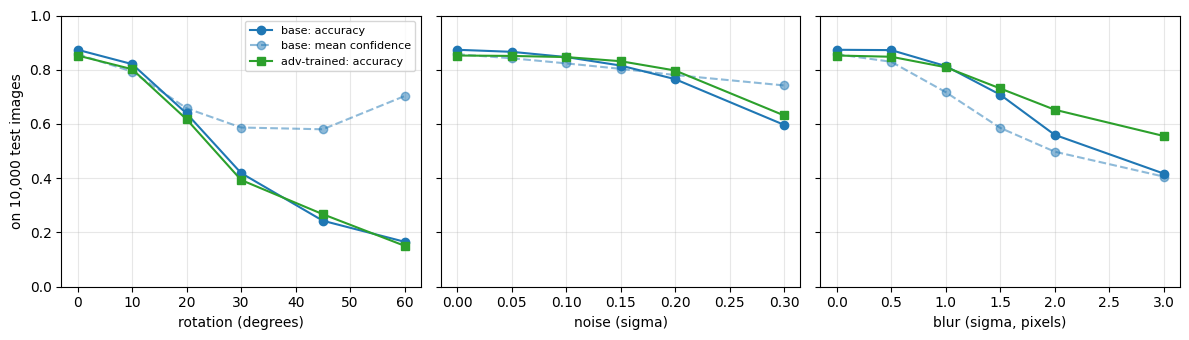

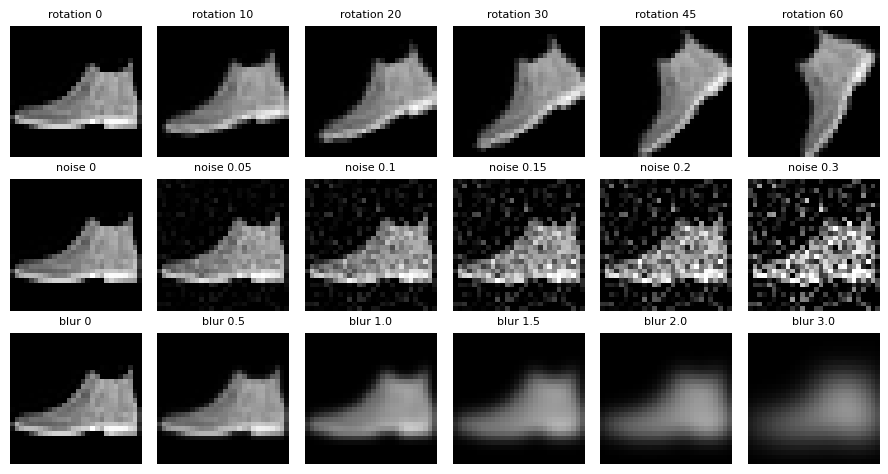

In [10]:
def rotate(x, degrees):
    if degrees == 0:
        return x
    a = np.deg2rad(degrees); c, s = np.cos(a), np.sin(a); mid = 13.5
    t = np.array([c, -s, mid - c * mid + s * mid, s, c, mid - s * mid - c * mid, 0, 0], "float32")
    out = keras.ops.image.affine_transform(x, np.tile(t, (len(x), 1)), interpolation="bilinear")
    return np.clip(np.array(out), 0.0, 1.0).astype("float32")

def add_noise(x, sigma, seed=1):
    if sigma == 0:
        return x
    return np.clip(x + np.random.default_rng(seed).normal(0, sigma, x.shape), 0.0, 1.0).astype("float32")

def blur(x, sigma):
    if sigma == 0:
        return x
    r = int(np.ceil(3 * sigma)); k = np.exp(-0.5 * (np.arange(-r, r + 1) / sigma) ** 2); k /= k.sum()
    f = np.pad(x[..., 0], ((0, 0), (r, r), (r, r)), mode="edge")
    f = sum(k[i] * f[:, i:i + 28, :] for i in range(2 * r + 1))
    f = sum(k[i] * f[:, :, i:i + 28] for i in range(2 * r + 1))
    return f[..., None].astype("float32")

SHIFTS = {
    "rotation (degrees)": (rotate, [0, 10, 20, 30, 45, 60]),
    "noise (sigma)": (add_noise, [0, 0.05, 0.1, 0.15, 0.2, 0.3]),
    "blur (sigma, pixels)": (blur, [0, 0.5, 1.0, 1.5, 2.0, 3.0]),
}
shift_acc = {}
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for a, (name, (fn, levels)) in zip(ax, SHIFTS.items()):
    accs_b, accs_r, confs = [], [], []
    for lv in levels:
        xs = fn(x_test, lv)
        pb = softmax(logits_of(base, xs))
        accs_b.append(accuracy(pb, y_test)); confs.append(float(pb.max(1).mean()))
        accs_r.append(acc_on(robust, xs, y_test))
    shift_acc[name] = (levels, accs_b, accs_r, confs)
    print(f"{name}\n   severity             " + "  ".join(f"{lv:>6}" for lv in levels))
    print("   base accuracy        " + "  ".join(f"{v:6.1%}" for v in accs_b))
    print("   base mean confidence " + "  ".join(f"{v:6.1%}" for v in confs))
    print("   adv-trained accuracy " + "  ".join(f"{v:6.1%}" for v in accs_r))
    a.plot(levels, accs_b, "o-", color="tab:blue", label="base: accuracy")
    a.plot(levels, confs, "o--", color="tab:blue", alpha=0.5, label="base: mean confidence")
    a.plot(levels, accs_r, "s-", color="tab:green", label="adv-trained: accuracy")
    a.set_xlabel(name); a.set_ylim(0, 1); a.grid(alpha=0.3)
ax[0].set_ylabel("on 10,000 test images"); ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(3, 6, figsize=(9, 4.8))
for r, (name, (fn, levels)) in enumerate(SHIFTS.items()):
    for c, lv in enumerate(levels):
        ax[r, c].imshow(fn(x_test[:1], lv)[0, ..., 0], cmap="gray", vmin=0, vmax=1); ax[r, c].axis("off")
        ax[r, c].set_title(f"{name.split(' ')[0]} {lv}", fontsize=8)
plt.tight_layout(); plt.show()

### Why we see this

The model was never shown a tilted, noisy or blurred image, and nothing in training asked it to cope with
one. Compare the dashed line with the solid one: where they part, the model's confidence has stopped tracking
its accuracy. And compare the green line with the blue: robustness is not one property. Training against
small pixel changes is training against one family of change.

---
# Part three: calibrate it

## Step 11 - Expected calibration error, first on a table you can check by hand

A model is **calibrated** if, among all the predictions it makes with confidence about 80%, about 80% are
right. To measure it: sort the predictions into bins by confidence; in each bin compare the **mean
confidence** with the **accuracy**; average the gaps, weighting each bin by its share of the predictions.
That average is the **expected calibration error** (ECE).

First a made-up table of 100 predictions in three bins, small enough to check with a pencil. Then the
function we will use on the real model, with ten bins.

> **Predict:** bins of 20, 30 and 50 predictions with gaps of 0.05, 0.10 and 0.08. What is the ECE?

In [11]:
toy = [("0.5 to 0.7", 20, 0.60, 0.55), ("0.7 to 0.9", 30, 0.80, 0.70), ("0.9 to 1.0", 50, 0.96, 0.88)]
total = sum(n for _, n, _, _ in toy)
ece_toy = 0.0
print("bin          count   mean confidence   accuracy    gap    share x gap")
for name, n, conf, acc in toy:
    ece_toy += n / total * abs(conf - acc)
    print(f"{name:11s} {n:5d} {conf:14.2f} {acc:12.2f} {abs(conf - acc):7.2f} {n / total * abs(conf - acc):10.3f}")
print(f"ECE = {ece_toy:.3f}")
print(f"overall: mean confidence {sum(n * c for _, n, c, _ in toy) / total:.3f}, accuracy {sum(n * a for _, n, _, a in toy) / total:.3f}")

def calibration_table(p, y, n_bins=10):
    conf, correct = p.max(1), (p.argmax(1) == y)
    edges = np.linspace(0, 1, n_bins + 1)
    rows, ece = [], 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            rows.append((lo, hi, int(m.sum()), float(conf[m].mean()), float(correct[m].mean())))
            ece += m.mean() * abs(conf[m].mean() - correct[m].mean())
    return rows, float(ece)

def ece_of(p, y):
    return calibration_table(p, y)[1]

bin          count   mean confidence   accuracy    gap    share x gap
0.5 to 0.7     20           0.60         0.55    0.05      0.010
0.7 to 0.9     30           0.80         0.70    0.10      0.030
0.9 to 1.0     50           0.96         0.88    0.08      0.040
ECE = 0.080
overall: mean confidence 0.840, accuracy 0.760


---
## Step 12 - The reliability diagram, and one temperature

The **reliability diagram** plots each bin's accuracy against its mean confidence. A calibrated model sits on
the diagonal. Bars **below** the diagonal mean over-confidence (it claims more than it delivers). Bars
**above** mean under-confidence.

The repair is one number. **Temperature scaling** (2017) divides every logit by a temperature `T` before the
softmax (Chapters 5 and 36 used the same knob for other purposes). `T` above 1 flattens the probabilities and
lowers the confidence; `T` below 1 sharpens them and raises it. We choose the `T` that gives the lowest
cross-entropy on the **validation** images, by trying every value from 0.30 to 4.00. The test set is not
consulted.

Dividing ten numbers by the same positive `T` cannot change which one is largest. So the predicted class, and
therefore the accuracy, must be exactly what it was. The cell asserts it.

> **Predict:** look back at Step 4's accuracy and mean confidence. Will the fitted `T` be above 1 or below 1?

BEFORE: the base model on the test set, T = 1
  confidence bin   count   mean confidence   accuracy   gap (confidence - accuracy)
  0.2 to 0.3        14          27.8%        28.6%        -0.7%
  0.3 to 0.4       141          36.0%        32.6%        +3.4%
  0.4 to 0.5       452          45.7%        45.8%        -0.1%
  0.5 to 0.6       743          55.0%        60.7%        -5.7%
  0.6 to 0.7       716          65.1%        71.1%        -6.0%
  0.7 to 0.8       885          75.3%        78.5%        -3.2%
  0.8 to 0.9      1141          85.2%        87.4%        -2.2%
  0.9 to 1.0      5908          98.2%        98.6%        -0.5%
  ECE 1.72%   accuracy 87.36%   mean confidence 85.73%   cross-entropy 0.3565



fitted temperature (on the validation set): T = 0.90

AFTER: the same logits divided by T
  confidence bin   count   mean confidence   accuracy   gap (confidence - accuracy)
  0.2 to 0.3         8          27.7%        50.0%       -22.3%
  0.3 to 0.4       118          36.3%        32.2%        +4.1%
  0.4 to 0.5       378          46.0%        42.6%        +3.4%
  0.5 to 0.6       661          55.1%        58.9%        -3.8%
  0.6 to 0.7       664          65.0%        67.2%        -2.2%
  0.7 to 0.8       768          75.2%        75.5%        -0.3%
  0.8 to 0.9      1128          85.1%        85.7%        -0.6%
  0.9 to 1.0      6275          98.3%        98.0%        +0.3%
  ECE 0.87%   accuracy 87.36%   mean confidence 87.22%   cross-entropy 0.3557

predicted classes identical before and after: accuracy unchanged, as it must be


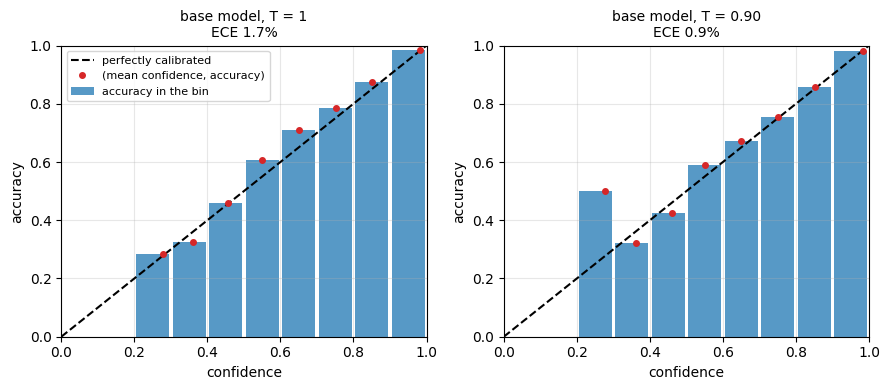

In [12]:
def fit_temperature(z, y):
    grid = np.arange(0.30, 4.0001, 0.01)
    losses = [nll(softmax(z, T), y) for T in grid]
    return float(grid[int(np.argmin(losses))])

def reliability_plot(ax, p, y, title):
    rows, e = calibration_table(p, y)
    mids = [(lo + hi) / 2 for lo, hi, *_ in rows]
    ax.bar(mids, [r[4] for r in rows], width=0.09, color="tab:blue", alpha=0.75, label="accuracy in the bin")
    ax.plot([0, 1], [0, 1], "k--", label="perfectly calibrated")
    ax.plot([r[3] for r in rows], [r[4] for r in rows], "o", color="tab:red", ms=4, label="(mean confidence, accuracy)")
    ax.set_xlabel("confidence"); ax.set_ylabel("accuracy"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_title(f"{title}\nECE {e:.1%}", fontsize=10); ax.grid(alpha=0.3)

def print_table(p, y):
    rows, e = calibration_table(p, y)
    print("  confidence bin   count   mean confidence   accuracy   gap (confidence - accuracy)")
    for lo, hi, n, c, a in rows:
        print(f"  {lo:.1f} to {hi:.1f} {n:9d} {c:14.1%} {a:12.1%} {c - a:+12.1%}")
    print(f"  ECE {e:.2%}   accuracy {accuracy(p, y):.2%}   mean confidence {p.max(1).mean():.2%}   cross-entropy {nll(p, y):.4f}")

print("BEFORE: the base model on the test set, T = 1")
print_table(p_test, y_test)

T_base = fit_temperature(z_val, y_val)                   # fitted on VALIDATION logits only
p_test_T = softmax(z_test, T_base)
print(f"\nfitted temperature (on the validation set): T = {T_base:.2f}")
print("\nAFTER: the same logits divided by T")
print_table(p_test_T, y_test)

assert (p_test.argmax(1) == p_test_T.argmax(1)).all()    # the ranking cannot change
assert accuracy(p_test, y_test) == accuracy(p_test_T, y_test)
print("\npredicted classes identical before and after: accuracy unchanged, as it must be")

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
reliability_plot(ax[0], p_test, y_test, "base model, T = 1")
reliability_plot(ax[1], p_test_T, y_test, f"base model, T = {T_base:.2f}")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

---
## Step 13 - The same check on a network that has memorised its training set

The published finding (2017) is that large modern networks, trained for a long time until they fit their
training data almost perfectly, are **over-confident**. Our base model is not that kind of network: it is
small, it trained for four passes, and it has dropout. So we make a second model that *is* a miniature of the
over-trained case: the same architecture with dropout off, trained for 60 passes on only 2,000 images until
it has nearly memorised them.

Then the same three things: the calibration table, one temperature fitted on validation data, the assertion.
The cell also measures how the base model's calibration holds up when the inputs shift (Step 10's rotation),
using the temperature fitted on clean validation data.

> **Predict:** for the memorising model, will the mean confidence be above or below the accuracy? Will its
> `T` be above 1 or below 1? And does a temperature fitted on clean data keep the base model calibrated on
> images rotated by 30 degrees?

memoriser: 60 passes over 2,000 images in 21s; final training accuracy 98.5%



BEFORE: the memoriser on the test set, T = 1
  confidence bin   count   mean confidence   accuracy   gap (confidence - accuracy)
  0.2 to 0.3         2          27.7%         0.0%       +27.7%
  0.3 to 0.4        26          36.7%        26.9%        +9.8%
  0.4 to 0.5       135          46.2%        32.6%       +13.6%
  0.5 to 0.6       419          55.0%        43.7%       +11.3%
  0.6 to 0.7       429          65.1%        48.5%       +16.6%
  0.7 to 0.8       518          75.2%        52.1%       +23.0%
  0.8 to 0.9       743          85.5%        61.0%       +24.5%
  0.9 to 1.0      7728          98.9%        88.3%       +10.6%
  ECE 12.60%   accuracy 79.88%   mean confidence 92.48%   cross-entropy 0.8746



fitted temperature (on the validation set): T = 2.62

AFTER
  confidence bin   count   mean confidence   accuracy   gap (confidence - accuracy)
  0.1 to 0.2         2          19.8%         0.0%       +19.8%
  0.2 to 0.3        42          27.3%        23.8%        +3.5%
  0.3 to 0.4       263          36.0%        34.6%        +1.4%
  0.4 to 0.5       739          45.5%        43.6%        +1.9%
  0.5 to 0.6      1027          55.0%        56.8%        -1.8%
  0.6 to 0.7      1032          65.0%        64.3%        +0.7%
  0.7 to 0.8      1138          75.0%        76.5%        -1.5%
  0.8 to 0.9      1262          85.2%        86.2%        -1.0%
  0.9 to 1.0      4495          97.5%        97.0%        +0.6%
  ECE 1.00%   accuracy 79.88%   mean confidence 79.92%   cross-entropy 0.5603


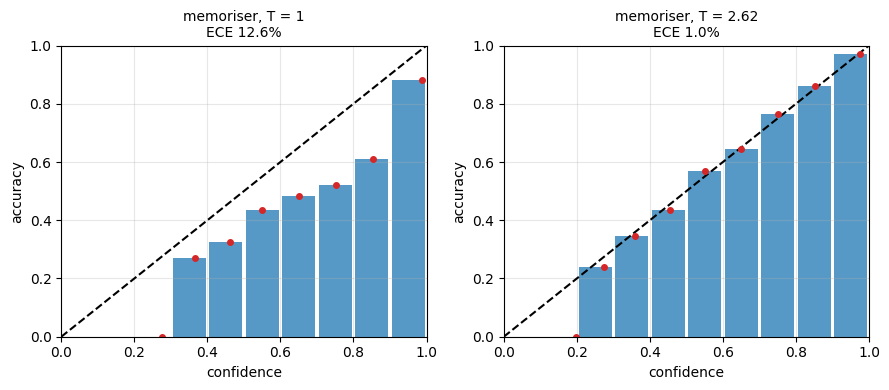


Does the base model's temperature survive a shift? (T fitted on clean validation images)
  rotation   accuracy   mean confidence (T=1)   ECE (T=1)   mean confidence (fitted T)   ECE (fitted T)


      0°      87.4%            85.7%             1.7%              87.2%                 0.9%


     10°      82.1%            79.3%             2.8%              81.3%                 0.9%


     20°      63.9%            65.8%             3.5%              68.2%                 4.9%


     30°      41.9%            58.7%            16.8%              61.3%                19.4%


     45°      24.3%            58.0%            33.7%              61.1%                36.7%


In [13]:
keras.utils.set_random_seed(SEED + 200)
overfit = compiled(build_model(dropout=0.0, name="memoriser"))
t0 = time.time()
h = overfit.fit(x_fit[:2000], y_fit[:2000], epochs=60, batch_size=64, verbose=0)
print(f"memoriser: 60 passes over 2,000 images in {time.time() - t0:.0f}s; final training accuracy {h.history['accuracy'][-1]:.1%}")

zo_val, zo_test = logits_of(overfit, x_val), logits_of(overfit, x_test)
po_test = softmax(zo_test)
print("\nBEFORE: the memoriser on the test set, T = 1")
print_table(po_test, y_test)
T_over = fit_temperature(zo_val, y_val)
po_test_T = softmax(zo_test, T_over)
print(f"\nfitted temperature (on the validation set): T = {T_over:.2f}")
print("\nAFTER")
print_table(po_test_T, y_test)
assert (po_test.argmax(1) == po_test_T.argmax(1)).all()

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
reliability_plot(ax[0], po_test, y_test, "memoriser, T = 1")
reliability_plot(ax[1], po_test_T, y_test, f"memoriser, T = {T_over:.2f}")
plt.tight_layout(); plt.show()

print("\nDoes the base model's temperature survive a shift? (T fitted on clean validation images)")
print("  rotation   accuracy   mean confidence (T=1)   ECE (T=1)   mean confidence (fitted T)   ECE (fitted T)")
for deg in [0, 10, 20, 30, 45]:
    zr = logits_of(base, rotate(x_test, deg))
    p1, pT = softmax(zr), softmax(zr, T_base)
    print(f"  {deg:5d}°   {accuracy(p1, y_test):8.1%} {p1.max(1).mean():16.1%} {ece_of(p1, y_test):16.1%} {pT.max(1).mean():18.1%} {ece_of(pT, y_test):20.1%}")

### Why we see this

Calibration is a property of a model **and** a kind of data, measured, never assumed. Two networks with the
same architecture came out on opposite sides of the diagonal, and one number moved each back, in opposite
directions, without touching the accuracy. And the last table says what a temperature is worth once the data
moves: it was fitted for the clean distribution, and it holds only there.

---
# Part four: know when it does not know

## Step 14 - Show it something that is not clothing

Now the handwritten digits. The model has ten outputs and a softmax, so the ten probabilities add up to one
whatever goes in. It has no way to answer "none of these".

The simplest out-of-distribution detector uses the model's own confidence: if the **maximum softmax
probability** is low, suspect the input. A second score, the **energy**, is the log of the sum of the
exponentials of the logits: it keeps the overall size of the logits, which softmax throws away.

To score a detector we use the **AUROC**: the chance that a randomly chosen clothing image gets a higher score
than a randomly chosen digit. 1.0 is a perfect detector, 0.5 is a coin.

> **Predict:** what is the model's mean confidence on the digits? What share of digits does it label with
> confidence above 90%? Which clothing class will it choose most often?

clothing (test): mean confidence 85.7%, share above 90% confident: 59.1%
digits (never seen): mean confidence 81.3%, share above 90% confident: 47.5%, above 99%: 22.9%
what the digits were called: Sandal 59%  Bag 24%  Sneaker 5%  Trouser 5%  T-shirt 3%
  digit 0: most often called Sandal    (80% of them), mean confidence 89%
  digit 1: most often called Sandal    (61% of them), mean confidence 72%
  digit 2: most often called Sandal    (46% of them), mean confidence 81%
  digit 3: most often called Sandal    (63% of them), mean confidence 80%
  digit 4: most often called Sandal    (47% of them), mean confidence 86%
  digit 5: most often called Sandal    (85% of them), mean confidence 91%
  digit 6: most often called Sandal    (51% of them), mean confidence 89%
  digit 7: most often called Sandal    (54% of them), mean confidence 75%
  digit 8: most often called Sandal    (48% of them), mean confidence 76%
  digit 9: most often called Sandal    (57% of them), mean confidence 77%

AUROC,

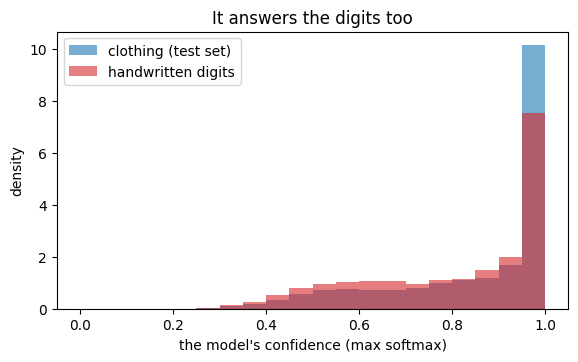

In [14]:
def auroc(in_scores, out_scores):
    """Chance that a random in-distribution score beats a random out-of-distribution score (ties count half)."""
    o = np.sort(out_scores)
    lo, hi = np.searchsorted(o, in_scores, side="left"), np.searchsorted(o, in_scores, side="right")
    return float((lo + 0.5 * (hi - lo)).mean() / len(o))

def energy(z):
    m = z.max(axis=1)
    return m + np.log(np.exp(z - m[:, None]).sum(axis=1))

z_ood = logits_of(base, x_ood)
p_ood = softmax(z_ood)
conf_in, conf_ood = p_test.max(1), p_ood.max(1)
print(f"clothing (test): mean confidence {conf_in.mean():.1%}, share above 90% confident: {(conf_in > 0.9).mean():.1%}")
print(f"digits (never seen): mean confidence {conf_ood.mean():.1%}, share above 90% confident: {(conf_ood > 0.9).mean():.1%}, above 99%: {(conf_ood > 0.99).mean():.1%}")
counts = np.bincount(p_ood.argmax(1), minlength=10)
print("what the digits were called:", "  ".join(f"{NAMES[c]} {counts[c] / len(p_ood):.0%}" for c in np.argsort(-counts)[:5]))
for d in range(10):
    pd_ = p_ood[y_digits == d]
    top = np.bincount(pd_.argmax(1), minlength=10).argmax()
    print(f"  digit {d}: most often called {NAMES[top]:9s} ({(pd_.argmax(1) == top).mean():.0%} of them), mean confidence {pd_.max(1).mean():.0%}")
print(f"\nAUROC, clothing against digits: max softmax {auroc(conf_in, conf_ood):.3f}   energy {auroc(energy(z_test), energy(z_ood)):.3f}")

plt.figure(figsize=(6.6, 3.6))
bins = np.linspace(0, 1, 21)
plt.hist(conf_in, bins=bins, alpha=0.6, color="tab:blue", label="clothing (test set)", density=True)
plt.hist(conf_ood, bins=bins, alpha=0.6, color="tab:red", label="handwritten digits", density=True)
plt.xlabel("the model's confidence (max softmax)"); plt.ylabel("density"); plt.legend()
plt.title("It answers the digits too"); plt.show()

---
## Step 15 - A small ensemble

One model gives one opinion. A **deep ensemble** (2017) trains the same architecture several times from
different random starting weights and averages the probabilities. Where the members agree, the average stays
sharp. Where they disagree, it flattens, and the disagreement itself is a measurement.

We train three more models exactly like the base model, each from **its own seed**, and use all four.

> **Predict:** will the ensemble's accuracy beat its best member's? What share of test images do the four
> members disagree on? Will that share be higher or lower on the digits?

In [15]:
members = [base]
t0 = time.time()
for k in range(1, 4):
    keras.utils.set_random_seed(SEED + k)               # a different start for every member
    m = compiled(build_model(name=f"member_{k}"))
    m.fit(x_fit, y_fit, epochs=EPOCHS, batch_size=128, verbose=0)
    members.append(m)
print(f"three more members trained in {time.time() - t0:.0f}s")

P_test = np.stack([softmax(logits_of(m, x_test)) for m in members])      # (4, 10000, 10)
P_ood = np.stack([softmax(logits_of(m, x_ood)) for m in members])
pe_test, pe_ood = P_test.mean(0), P_ood.mean(0)

print("\n               accuracy   cross-entropy    ECE")
for k in range(4):
    print(f"member {k}       {accuracy(P_test[k], y_test):8.2%} {nll(P_test[k], y_test):12.4f} {ece_of(P_test[k], y_test):9.2%}")
print(f"ensemble of 4  {accuracy(pe_test, y_test):8.2%} {nll(pe_test, y_test):12.4f} {ece_of(pe_test, y_test):9.2%}")

votes_test, votes_ood = P_test.argmax(2), P_ood.argmax(2)
dis_test = (votes_test != votes_test[0]).any(0)
dis_ood = (votes_ood != votes_ood[0]).any(0)
ens_right = pe_test.argmax(1) == y_test
print(f"\nmembers disagree on the class for {dis_test.mean():.1%} of clothing images and {dis_ood.mean():.1%} of digits")
print(f"ensemble accuracy where all four agree: {ens_right[~dis_test].mean():.1%}; where they disagree: {ens_right[dis_test].mean():.1%}")

three more members trained in 77s



               accuracy   cross-entropy    ECE
member 0         87.36%       0.3565     1.72%
member 1         87.66%       0.3481     1.24%
member 2         87.89%       0.3385     1.26%
member 3         87.77%       0.3418     1.35%
ensemble of 4    88.14%       0.3329     2.27%

members disagree on the class for 9.7% of clothing images and 48.0% of digits
ensemble accuracy where all four agree: 92.1%; where they disagree: 51.0%


---
## Step 16 - MC dropout, and two kinds of uncertainty

**MC dropout** (2016) gets several opinions out of one trained model. Call the model with `training=True`:
dropout stays on, a different random 30% of the Flatten outputs are zeroed each time, and each call is a
slightly different network. Average 30 calls.

With several opinions you can split uncertainty in two (the split is the same for an ensemble and for MC
dropout):

- **total** = the entropy of the averaged probabilities: how spread out the final answer is.
- **data (aleatoric) part** = the average entropy of each member: every member, on its own, finds the image
  ambiguous. A shirt that could be a T-shirt.
- **knowledge (epistemic) part** = total minus that: the members are each fairly sure and **disagree**.
  This is the part that more data, or data of a new kind, would reduce.

The table at the end scores five ways of telling clothing from digits.

> **Predict:** for which group will the knowledge part be largest: clothing the ensemble gets right, clothing
> it gets wrong, or digits?

In [16]:
def mc_dropout(model, x, passes=30, batch=5000):
    out = np.zeros((passes, len(x), 10), "float32")
    for t in range(passes):
        for i in range(0, len(x), batch):
            out[t, i:i + batch] = softmax(model(x[i:i + batch], training=True).numpy())     # dropout left ON
    return out

t0 = time.time()
M_test, M_ood = mc_dropout(base, x_test), mc_dropout(base, x_ood)
pm_test, pm_ood = M_test.mean(0), M_ood.mean(0)
print(f"30 dropout passes over 20,000 images took {time.time() - t0:.0f}s")
print(f"one pass with dropout on: accuracy {accuracy(M_test[0], y_test):.2%}")
print(f"mean of 30 passes:        accuracy {accuracy(pm_test, y_test):.2%}  cross-entropy {nll(pm_test, y_test):.4f}  ECE {ece_of(pm_test, y_test):.2%}")
print(f"dropout off (Step 4):     accuracy {accuracy(p_test, y_test):.2%}  cross-entropy {nll(p_test, y_test):.4f}  ECE {ece_of(p_test, y_test):.2%}")

def entropy(p):
    return -(p * np.log(p + 1e-12)).sum(-1)

def split(P):                                            # P has shape (members, images, classes)
    total = entropy(P.mean(0))
    data = entropy(P).mean(0)
    return total, data, total - data

print("\nEnsemble of 4: mean uncertainty in nats (the most possible is ln 10 = 2.303)")
print("                              images    total    data part   knowledge part")
tot, dat, kno = split(P_test)
for name, mask in [("clothing, ensemble right", ens_right), ("clothing, ensemble wrong", ~ens_right)]:
    print(f"{name:27s} {mask.sum():8d} {tot[mask].mean():8.3f} {dat[mask].mean():10.3f} {kno[mask].mean():13.3f}")
tot_o, dat_o, kno_o = split(P_ood)
print(f"{'handwritten digits':27s} {len(tot_o):8d} {tot_o.mean():8.3f} {dat_o.mean():10.3f} {kno_o.mean():13.3f}")
_, _, kno_m = split(M_test); _, _, kno_mo = split(M_ood)

print("\nAUROC for telling clothing from digits (1.0 perfect, 0.5 a coin):")
scores = [
    ("one model, max softmax", conf_in, conf_ood),
    ("one model, energy", energy(z_test), energy(z_ood)),
    ("MC dropout, max of the mean", pm_test.max(1), pm_ood.max(1)),
    ("MC dropout, knowledge part", -kno_m, -kno_mo),
    ("ensemble, max of the mean", pe_test.max(1), pe_ood.max(1)),
    ("ensemble, knowledge part", -kno, -kno_o),
]
for name, a, b in scores:
    print(f"  {name:30s} {auroc(a, b):.3f}")
print(f"\ndigits labelled with confidence above 90%: one model {(conf_ood > 0.9).mean():.1%}, MC dropout {(pm_ood.max(1) > 0.9).mean():.1%}, ensemble {(pe_ood.max(1) > 0.9).mean():.1%}")

30 dropout passes over 20,000 images took 29s
one pass with dropout on: accuracy 85.60%
mean of 30 passes:        accuracy 87.16%  cross-entropy 0.3616  ECE 3.21%
dropout off (Step 4):     accuracy 87.36%  cross-entropy 0.3565  ECE 1.72%

Ensemble of 4: mean uncertainty in nats (the most possible is ln 10 = 2.303)
                              images    total    data part   knowledge part
clothing, ensemble right        8814    0.312      0.300         0.011
clothing, ensemble wrong        1186    0.914      0.878         0.036
handwritten digits             10000    0.670      0.519         0.151

AUROC for telling clothing from digits (1.0 perfect, 0.5 a coin):
  one model, max softmax         0.583
  one model, energy              0.595
  MC dropout, max of the mean    0.649
  MC dropout, knowledge part     0.839
  ensemble, max of the mean      0.665
  ensemble, knowledge part       0.828

digits labelled with confidence above 90%: one model 47.5%, MC dropout 32.0%, ensemble 34.0%


### Why we see this

Three things, and the second is not the usual story. First, one model's confidence hardly separates clothing
from digits (an AUROC near 0.5 is a coin), while the **disagreement** between several opinions separates them
much better: the members were never told what to do with a digit, so each does something different. Second,
averaging made the calibration error **worse** here. Each member is already a little under-confident, and an
average of probabilities is flatter than its parts, so the ensemble is more under-confident still. Published
ensembles of large over-confident networks gain calibration for the same reason ours loses it. Third, the
digits still collect plenty of confident answers from every method. These scores help. None of them is a wall.

---
## Step 17 - Back to Part one for a moment: do adversarial images transfer?

In Part one the attacker had the model's gradient: a **white-box** attack. Suppose the attacker has no access
to the model being served, and instead trains a look-alike and attacks that. Do images built to fool one
network fool another that was trained separately? This is a **black-box transfer** attack, and we now have
the models to try it: the adversarial images were built against member 0 only.

> **Predict:** FGSM images built against member 0 at `eps = 0.05` and `0.1`. What accuracy will members 1 to 3
> have on them: nearly their clean accuracy, or nearly as bad as member 0? And the whole ensemble?

In [17]:
print("  eps   member 0 (attacked)   member 1   member 2   member 3   ensemble of 4   robust model   random signs (member 1)")
for eps in [0.05, 0.1]:
    xa = fgsm(base, x_att, y_att, eps)
    accs = [acc_on(m, xa, y_att) for m in members]
    ens = accuracy(np.mean([softmax(logits_of(m, xa)) for m in members], axis=0), y_att)
    print(f"{eps:5.2f} {accs[0]:14.1%} {accs[1]:15.1%} {accs[2]:10.1%} {accs[3]:10.1%} {ens:12.1%} {acc_on(robust, xa, y_att):14.1%}"
          f" {acc_on(members[1], random_signs(x_att, eps), y_att):16.1%}")
print("clean accuracy on the same 2,000 images:", "  ".join(f"member {k} {acc_on(m, x_att, y_att):.1%}" for k, m in enumerate(members)))

  eps   member 0 (attacked)   member 1   member 2   member 3   ensemble of 4   robust model   random signs (member 1)


 0.05          51.9%           66.7%      67.0%      69.8%        64.7%          79.8%            88.2%


 0.10          22.6%           36.9%      38.0%      46.8%        36.0%          68.6%            87.1%


clean accuracy on the same 2,000 images: member 0 88.5%  member 1 88.6%  member 2 88.6%  member 3 88.8%


---
## Step 18 - Abstain: the accuracy-coverage curve

A model that may say "I am not sure, ask a person" can be more accurate on what it does answer. This is
**selective prediction**. The rule: answer only when the confidence is at least a threshold. **Coverage** is
the share of inputs answered. Raise the threshold and coverage falls while accuracy on the answered part
rises.

The threshold is a decision, so it is made on the **validation** set: the lowest confidence at which the
answered validation images are at least 95% right. Then we see what that rule does on the test set, on the
digits, and on the adversarial images of Step 7.

> **Predict:** to be 95% right on what it answers, what share of the test set must the base model give up?
> And the hard one: of the adversarial images, what share will the rule refuse?

threshold chosen on validation for 95% accuracy on what is answered: confidence >= 0.716
test set: answers 80.5%, accuracy on those 94.5%; abstains on 19.5%, where it would have been 57.9% right

  coverage   one model   ensemble of 4
     100%      87.4%         88.1%
      90%      91.5%         92.6%
      80%      94.6%         95.5%
      70%      96.9%         97.4%
      60%      98.5%         98.8%
      50%      99.2%         99.4%

the same rule on the digits: answers 72.9% of them (every answer is wrong)
the same rule on the FGSM images (eps 0.05): answers 63.9%; of its 962 mistakes there, 53.2% pass the threshold
the ensemble's confidence on the digits: 54.4% would pass the same threshold


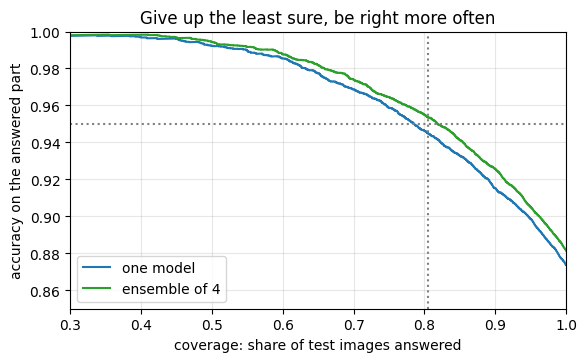

In [18]:
def coverage_curve(conf, correct):
    order = np.argsort(-conf)
    acc_at = np.cumsum(correct[order]) / np.arange(1, len(conf) + 1)
    return np.arange(1, len(conf) + 1) / len(conf), acc_at

def threshold_for(conf, correct, target):
    order = np.argsort(-conf)
    acc_at = np.cumsum(correct[order]) / np.arange(1, len(conf) + 1)
    ok = np.where(acc_at >= target)[0]
    return float(conf[order][ok[-1]])                    # the lowest confidence that still meets the target

p_val_T = softmax(z_val, T_base)
conf_val, right_val = p_val_T.max(1), p_val_T.argmax(1) == y_val
conf_T, right_T = p_test_T.max(1), p_test_T.argmax(1) == y_test
TARGET = 0.95
thr = threshold_for(conf_val, right_val, TARGET)
print(f"threshold chosen on validation for {TARGET:.0%} accuracy on what is answered: confidence >= {thr:.3f}")
answered = conf_T >= thr
print(f"test set: answers {answered.mean():.1%}, accuracy on those {right_T[answered].mean():.1%}; "
      f"abstains on {(~answered).mean():.1%}, where it would have been {right_T[~answered].mean():.1%} right")

cov, acc_c = coverage_curve(conf_T, right_T)
cov_e, acc_e = coverage_curve(pe_test.max(1), ens_right)
print("\n  coverage   one model   ensemble of 4")
for c in [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]:
    i = int(round(c * len(cov))) - 1
    print(f"  {c:7.0%} {acc_c[i]:10.1%} {acc_e[i]:13.1%}")

conf_ood_T = softmax(z_ood, T_base).max(1)
p_adv_T = softmax(logits_of(base, x_adv), T_base)
adv_wrong = p_adv_T.argmax(1) != y_att
print(f"\nthe same rule on the digits: answers {(conf_ood_T >= thr).mean():.1%} of them (every answer is wrong)")
print(f"the same rule on the FGSM images (eps {EPS_SHOW}): answers {(p_adv_T.max(1) >= thr).mean():.1%}; "
      f"of its {adv_wrong.sum()} mistakes there, {(p_adv_T.max(1)[adv_wrong] >= thr).mean():.1%} pass the threshold")
print(f"the ensemble's confidence on the digits: {(pe_ood.max(1) >= thr).mean():.1%} would pass the same threshold")

plt.figure(figsize=(6.4, 3.6))
plt.plot(cov, acc_c, color="tab:blue", label="one model")
plt.plot(cov_e, acc_e, color="tab:green", label="ensemble of 4")
plt.axvline(answered.mean(), color="grey", ls=":"); plt.axhline(TARGET, color="grey", ls=":")
plt.xlim(0.3, 1.0); plt.ylim(0.85, 1.0); plt.xlabel("coverage: share of test images answered")
plt.ylabel("accuracy on the answered part"); plt.grid(alpha=0.3); plt.legend(); plt.title("Give up the least sure, be right more often"); plt.show()

---
## Step 19 - Prediction sets with a guarantee: conformal prediction

Abstaining is all or nothing. **Conformal prediction** gives a middle answer: a **set** of labels ("Shirt or
T-shirt") built so that the true label is inside at a rate you choose in advance, for example 90%.

The split version takes a few lines. On the validation set, score every image by `1 - (probability given to
its true class)`: how surprised the model was. Find the score that 90% of validation images stay under (with
a small correction for the finite sample). For a new image, put in the set every class the model gives at
least `1 - that score`.

The guarantee has one assumption: the new images and the validation images are **exchangeable**, which in
practice means drawn from the same source. The last lines break that assumption on purpose.

> **Predict:** asked for 90% coverage, how many labels will the average set hold? And if the test images are
> rotated by 20 degrees, will the sets still contain the truth 90% of the time?

In [19]:
def conformal_threshold(p_cal, y_cal, alpha):
    scores = 1.0 - p_cal[np.arange(len(y_cal)), y_cal]
    n = len(scores)
    level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    return float(np.quantile(scores, level, method="higher"))

def report_sets(p, y, q):
    sets = p >= 1.0 - q
    covered = sets[np.arange(len(y)), y].mean()
    size = sets.sum(1)
    return covered, size.mean(), (size == 1).mean(), (size == 0).mean(), (size >= 3).mean()

print("  asked for   threshold q   true label in the set   mean set size   one label   empty   three or more")
for alpha in [0.10, 0.05, 0.01]:
    q = conformal_threshold(p_val_T, y_val, alpha)
    c, s, one, empty, big = report_sets(p_test_T, y_test, q)
    print(f"  {1 - alpha:8.0%} {q:12.3f} {c:18.1%} {s:17.2f} {one:13.1%} {empty:8.1%} {big:11.1%}")

q90 = conformal_threshold(p_val_T, y_val, 0.10)
sets = p_test_T >= 1.0 - q90
i = int(np.where(sets.sum(1) == 2)[0][0])
print(f"\nan example set of two, test image {i}: {[NAMES[c] for c in np.where(sets[i])[0]]}, true label {NAMES[y_test[i]]}")
print("\nThe 90% sets when the assumption is broken (threshold still from clean validation images):")
for deg in [0, 10, 20, 30]:
    pr = softmax(logits_of(base, rotate(x_test, deg)), T_base)
    c, s, one, empty, big = report_sets(pr, y_test, q90)
    print(f"  rotated {deg:2d}°: true label in the set {c:.1%}, mean set size {s:.2f}")

print(f"\nwhole notebook: {time.time() - t_start:.0f}s")

  asked for   threshold q   true label in the set   mean set size   one label   empty   three or more
       90%        0.639              89.6%              1.06         93.4%     0.5%        0.0%
       95%        0.824              94.4%              1.25         77.3%     0.0%        2.4%
       99%        0.979              98.9%              1.89         48.9%     0.0%       26.7%

an example set of two, test image 6: ['Coat', 'Shirt'], true label Coat

The 90% sets when the assumption is broken (threshold still from clean validation images):


  rotated  0°: true label in the set 89.6%, mean set size 1.06


  rotated 10°: true label in the set 83.9%, mean set size 1.04


  rotated 20°: true label in the set 64.0%, mean set size 0.99


  rotated 30°: true label in the set 38.3%, mean set size 0.88

whole notebook: 273s


---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | In Step 9 set `EPS_TRAIN = 0.1` and rerun Steps 9 and 10 | Clean accuracy up or down? PGD 0.10 accuracy? | |
| 2 | In Step 8 call `pgd(..., steps=40)` | Much lower than 10 steps, or about the same? | |
| 3 | In Step 3 set `dropout=0.0` for the base model and rerun to Step 12 | Does `T` move towards 1, past it, or away? | |
| 4 | Set `EPOCHS = 12` and rerun everything (about ten minutes) | Which way does the base model's `T` move? | |
| 5 | In Step 12 fit `T` on `z_test` instead of `z_val` | How different is `T`? Why is it still wrong to do? | |
| 6 | In Step 15 give every member the same seed | What happens to the disagreement and the knowledge part? | |
| 7 | In Step 18 set `TARGET = 0.99` | How much coverage is left? | |
| 8 | In Step 14 use `1 - x_ood` (dark digits on white) as the outsiders | Easier or harder to detect? | |

## Exercises

1. **A targeted attack.** FGSM as written pushes the loss of the true class up. Change it to push the loss of
   a class *you* choose down (`x - eps * sign(gradient of the loss for the target label)`). How often can you
   turn a Trouser into a Bag at `eps = 0.1`?
2. **Augment instead.** Train a model on images rotated by a random angle between -30 and 30 degrees
   (`layers.RandomRotation(30 / 360)` as the first layer). Redraw Step 10's rotation curve. What did it cost
   on clean images, and did it help with blur?
3. **Label smoothing.** Compile the base model with a categorical loss and `label_smoothing=0.1` (one-hot the
   labels first). What happens to its mean confidence, its ECE and its fitted temperature?
4. **Calibration per class.** Compute the ECE separately for images the model calls Shirt and for images it
   calls Trouser. Does one temperature suit both?
5. **A harder outsider.** Train on eight clothing classes and treat the other two as out-of-distribution.
   Compare the AUROC with the one for digits. Which test tells you more about a real deployment?
6. **Conformal under attack.** Build the 90% sets for the FGSM images of Step 7. How often is the true label
   inside? Which assumption was broken?

## Cheat sheet

| Idea | One line | Code |
|---|---|---|
| FGSM | one step of size `eps` along the sign of the input gradient | `x + eps * sign(tape.gradient(loss, x))` |
| PGD | many small sign steps, projected back into the `eps` box, random start | `clip(xa, x - eps, x + eps)` |
| Adversarial training | attack the current model every step, train on clean + attacked | `adversarial_step` |
| ECE | share-weighted mean of the gap between confidence and accuracy over bins | `calibration_table` |
| Temperature scaling | divide logits by one `T` fitted on validation data; ranking unchanged | `softmax(z, T)` |
| Max softmax / energy | simplest out-of-distribution scores | `p.max(1)`, `energy(z)` |
| Deep ensemble | same model, different seeds, average the probabilities | `P.mean(0)` |
| MC dropout | call with `training=True` many times, average | `model(x, training=True)` |
| Data / knowledge split | mean member entropy / total entropy minus that | `split(P)` |
| Selective prediction | answer only when confidence is at least a threshold set on validation data | `threshold_for` |
| Conformal set | every class with probability at least `1 - q`; `q` from validation scores | `conformal_threshold` |